# T09 — Small multi-particle, multi-forcing-member Stage III run, manual check

Scope (per `tasks.md` T09 and the 2026-09-22 task instructions): run the *existing,
unmodified* T05/T06 backward-adjoint pipeline for a small set of upstream particles
(T07's `adapt_upstream_particles`) across a small set of forcing members (T08's
`ForcingEnsemble`), and record `(particle, forcing_member, checkpoint)` rows with
`timestamp`, `lat`, `lon`, `log_weight`, `observation_pixel_id`, `forcing_member_id`,
`valid`. No particle generation, no T10 diagnostics module, no KDE/likelihood/SMC/MCMC/
AIS, no production-scale run.

**Every forcing-member perturbation used here is still the T08 PROTOTYPE — NOT
VALIDATED — model.**

In [1]:
import os
import sys
import time

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.environment import load_field_dataset
from iste.observation import adapt_upstream_particles
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.ensemble_run import run_ensemble, compute_diagnostics, compute_diagnostics_by_member

OCEAN_PATH = os.path.join(REPO_ROOT, "data", "ocean.nc")
ocean = load_field_dataset(OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="latitude", lon_dim="longitude")

c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

## 1. Small smoke-test configuration

Documented, deliberately small development values -- **not** `E=50` at production
particle counts.

In [2]:
t0 = ocean.time[50]  # an arbitrary real observation instant

# a mock stand-in for T07's upstream particle payload -- 4 particles from 2 observation
# pixels, one already marked invalid by the (hypothetical) upstream teammate module.
mock_upstream_payload = [
    {"particle_id": "p0", "latitude": 33.0, "longitude": 30.0, "observation_pixel_id": "px-0", "timestamp": t0},
    {"particle_id": "p1", "latitude": 33.15, "longitude": 30.15, "observation_pixel_id": "px-0", "timestamp": t0},
    {"particle_id": "p2", "latitude": 34.0, "longitude": 31.0, "observation_pixel_id": "px-1", "timestamp": t0},
    {"particle_id": "p3", "latitude": 34.1, "longitude": 31.1, "observation_pixel_id": "px-1", "timestamp": t0, "valid": False},
]
particles = adapt_upstream_particles(mock_upstream_payload)

N_MEMBERS_TOTAL = 5      # small ensemble (not E=50)
FORCING_MEMBER_IDS = [0, 1, 2]   # use only 3 of the 5 configured members for this run
N_STEPS = 8               # small window
DT_SECONDS = 900.0        # 15-minute checkpoints (within the README-required 15-30 min range)

ensemble = ForcingEnsemble(ocean, ForcingEnsembleConfig(n_members=N_MEMBERS_TOTAL, master_seed=7))
k_field = np.zeros((len(ocean.lat), len(ocean.lon)))  # K still undefined -- synthetic zero field

print(f"{particles.n_particles} particles x {len(FORCING_MEMBER_IDS)} forcing members x "
      f"{N_STEPS + 1} checkpoints ({N_STEPS} steps of {DT_SECONDS/60:.0f} min)")
print(f"backward window: {N_STEPS * DT_SECONDS / 3600:.2f} hours")

4 particles x 3 forcing members x 9 checkpoints (8 steps of 15 min)
backward window: 2.00 hours


## 2. Run it, and measure runtime / memory

In [3]:
t_start = time.time()
records = run_ensemble(
    particles, FORCING_MEMBER_IDS, N_STEPS, DT_SECONDS, ocean, ensemble,
    ocean.lat, ocean.lon, k_field, master_seed=42,
)
elapsed = time.time() - t_start

records_bytes = (
    records.timestamp.nbytes + records.lat.nbytes + records.lon.nbytes
    + records.log_weight.nbytes + records.valid.nbytes
    + sum(len(str(x)) for x in records.particle_id) + sum(len(str(x)) for x in records.observation_pixel_id)
)
cached_env_bytes = sum(ensemble.member_state_nbytes(m) for m in FORCING_MEMBER_IDS)

print(f"runtime: {elapsed:.3f} s for {records.n_records} records")
print(f"records memory (approx): {records_bytes/1024:.1f} KB")
print(f"forcing-ensemble cached state ({len(FORCING_MEMBER_IDS)} members): {cached_env_bytes/1024/1024:.2f} MB")
print("(base uo/vo arrays are referenced, not duplicated; no full perturbed grid is stored for any member.)")

runtime: 0.467 s for 84 records
records memory (approx): 3.2 KB
forcing-ensemble cached state (3 members): 18.92 MB
(base uo/vo arrays are referenced, not duplicated; no full perturbed grid is stored for any member.)


## 3. Trajectory examples: forcing-member IDs and observation-pixel IDs

In [4]:
print(f"{'particle_id':>11} {'member':>6} {'pixel_id':>8} {'checkpoints':>11}")
for pid in np.unique(records.particle_id):
    for member_id in FORCING_MEMBER_IDS:
        mask = (records.particle_id == pid) & (records.forcing_member_id == member_id)
        n = int(np.sum(mask))
        pixel = records.observation_pixel_id[mask][0]
        print(f"{pid:>11} {member_id:>6} {str(pixel):>8} {n:>11}")

particle_id member pixel_id checkpoints
         p0      0     px-0           9
         p0      1     px-0           9
         p0      2     px-0           9
         p1      0     px-0           9
         p1      1     px-0           9
         p1      2     px-0           9
         p2      0     px-1           9
         p2      1     px-1           9
         p2      2     px-1           9
         p3      0     px-1           1
         p3      1     px-1           1
         p3      2     px-1           1


### Trajectory Visualization (Absolute Positions)

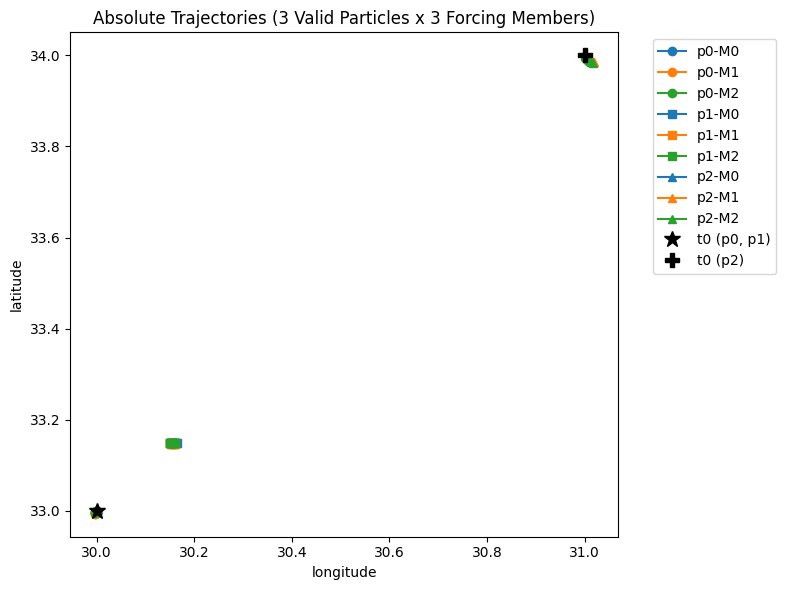

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}
markers = {"p0": "o", "p1": "s", "p2": "^"}

for pid in ["p0", "p1", "p2"]:
    for member_id in FORCING_MEMBER_IDS:
        mask = (records.particle_id == pid) & (records.forcing_member_id == member_id)
        ax.plot(records.lon[mask], records.lat[mask], marker=markers[pid], linestyle='-', color=colors[member_id], label=f"{pid}-M{member_id}")

# Mark initial positions (t0)
t0_mask_01 = (np.isin(records.particle_id, ["p0", "p1"])) & (records.forcing_member_id == FORCING_MEMBER_IDS[0])
ax.plot(records.lon[t0_mask_01][0], records.lat[t0_mask_01][0], "k*", markersize=12, label="t0 (p0, p1)")
t0_mask_2 = (records.particle_id == "p2") & (records.forcing_member_id == FORCING_MEMBER_IDS[0])
ax.plot(records.lon[t0_mask_2][0], records.lat[t0_mask_2][0], "kP", markersize=10, label="t0 (p2)")

ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Absolute Trajectories (3 Valid Particles x 3 Forcing Members)")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Trajectory Visualization (Relative Displacements)

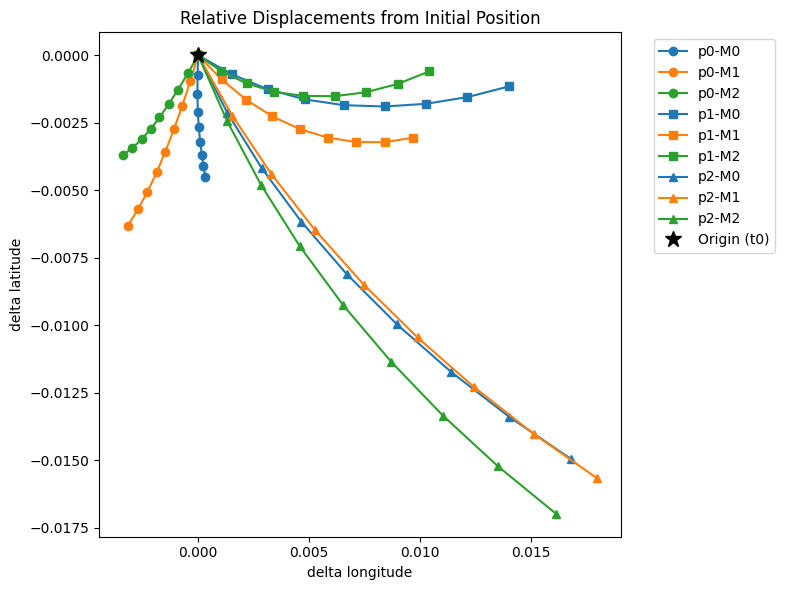

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

for pid in ["p0", "p1", "p2"]:
    for member_id in FORCING_MEMBER_IDS:
        mask = (records.particle_id == pid) & (records.forcing_member_id == member_id)
        lons = np.array(records.lon[mask])
        lats = np.array(records.lat[mask])
        
        delta_lon = lons - lons[0]
        delta_lat = lats - lats[0]
        ax.plot(delta_lon, delta_lat, marker=markers[pid], linestyle='-', color=colors[member_id], label=f"{pid}-M{member_id}")
        
ax.plot([0], [0], "k*", markersize=12, label="Origin (t0)")
ax.set_xlabel("delta longitude")
ax.set_ylabel("delta latitude")
ax.set_title("Relative Displacements from Initial Position")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 4. Forcing-Member / Time Structure Diagnostic

In [7]:
print("Forcing Member / Time Checkpoint Structure:\n")
print(f"{'checkpoint':<12} {'timestamp':<25} {'forcing_members'}")

# Use valid records to find unique timestamps
valid_mask = np.isin(records.particle_id, ["p0", "p1", "p2"])
unique_times = np.unique(np.array(records.timestamp[valid_mask]))

# Checkpoints evaluate progressively forward in the array (backward in physical time)
for i, t in enumerate(unique_times):
    t_mask = records.timestamp == t
    members_at_t = np.unique(np.array(records.forcing_member_id[t_mask & valid_mask]))
    print(f"{i:<12} {str(t):<25} {list(members_at_t)}")

Forcing Member / Time Checkpoint Structure:

checkpoint   timestamp                 forcing_members
0            2019-10-03T00:00:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
1            2019-10-03T00:15:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
2            2019-10-03T00:30:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
3            2019-10-03T00:45:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
4            2019-10-03T01:00:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
5            2019-10-03T01:15:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
6            2019-10-03T01:30:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
7            2019-10-03T01:45:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]
8            2019-10-03T02:00:00.000000000 [np.int64(0), np.int64(1), np.int64(2)]


## 5. Weight Evaluation

The log-weight of each particle is updated incrementally using the T05 divergence-based formulation:

$$\text{log\_w\_new} = \text{log\_w\_old} - \text{divergence}(U) \times dt$$

**Explanation:**
- `log_weight` starts from the existing initial value.
- At every backward timestep, divergence is evaluated along the trajectory.
- The weight is updated incrementally.
- Convergence (negative divergence) increases `log_weight`.
- Divergence (positive divergence) decreases `log_weight`.
- Each particle/member trajectory therefore accumulates its own distinct weight history.

**Important:**
The forcing member is evaluated at every timestep. "Member 0" does NOT mean one fixed force applied only at t0. It means the particle follows forcing realization 0 continuously through the entire time interval.

In [8]:
print(f"{'particle_id':<12} {'forcing_member':<15} {'checkpoint':<12} {'time':<10} {'latitude':<10} {'longitude':<10} {'log_weight':<12} {'weight'}")
print("-" * 100)
for pid in ["p0", "p1", "p2"]:
    for member_id in FORCING_MEMBER_IDS:
        mask = (records.particle_id == pid) & (records.forcing_member_id == member_id)
        p_lats = np.array(records.lat[mask])
        p_lons = np.array(records.lon[mask])
        p_lw = np.array(records.log_weight[mask])
        
        for chkpt in range(len(p_lw)):
            lw = p_lw[chkpt]
            w = np.exp(lw)
            print(f"{pid:<12} {member_id:<15} {chkpt:<12} {chkpt:<10} {p_lats[chkpt]:<10.4f} {p_lons[chkpt]:<10.4f} {lw:<12.6f} {w:.6f}")

particle_id  forcing_member  checkpoint   time       latitude   longitude  log_weight   weight
----------------------------------------------------------------------------------------------------
p0           0               0            0          33.0000    30.0000    0.000000     1.000000
p0           0               1            1          32.9993    30.0000    0.002873     1.002877
p0           0               2            2          32.9986    30.0000    0.006270     1.006289
p0           0               3            3          32.9979    30.0000    0.010184     1.010236
p0           0               4            4          32.9973    30.0000    0.014610     1.014717
p0           0               5            5          32.9968    30.0001    0.019542     1.019734
p0           0               6            6          32.9963    30.0002    0.024582     1.024887
p0           0               7            7          32.9959    30.0002    0.029725     1.030172
p0           0              

### Log-Weight vs Time Plot

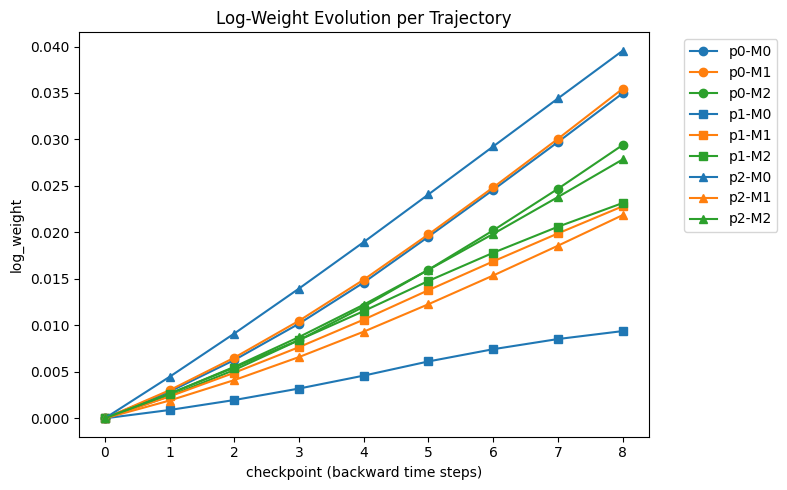

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

for pid in ["p0", "p1", "p2"]:
    for member_id in FORCING_MEMBER_IDS:
        mask = (records.particle_id == pid) & (records.forcing_member_id == member_id)
        p_lw = np.array(records.log_weight[mask])
        checkpoints = np.arange(len(p_lw))
        ax.plot(checkpoints, p_lw, marker=markers[pid], linestyle='-', color=colors[member_id], label=f"{pid}-M{member_id}")
        
ax.set_xlabel("checkpoint (backward time steps)")
ax.set_ylabel("log_weight")
ax.set_title("Log-Weight Evolution per Trajectory")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Weight Diagnostic Summary

In [10]:
print(f"{'particle':<10} {'member':<8} {'chkpts':<8} {'init_log_w':<12} {'final_log_w':<12} {'init_w':<10} {'final_w':<10} {'delta_log_w':<12}")
print("-" * 95)
for pid in ["p0", "p1", "p2"]:
    for member_id in FORCING_MEMBER_IDS:
        mask = (records.particle_id == pid) & (records.forcing_member_id == member_id)
        p_lw = np.array(records.log_weight[mask])
        chkpts = len(p_lw)
        if chkpts > 0:
            ilw = p_lw[0]
            flw = p_lw[-1]
            iw = np.exp(ilw)
            fw = np.exp(flw)
            dlw = flw - ilw
            print(f"{pid:<10} {member_id:<8} {chkpts:<8} {ilw:<12.6f} {flw:<12.6f} {iw:<10.6f} {fw:<10.6f} {dlw:<12.6f}")

particle   member   chkpts   init_log_w   final_log_w  init_w     final_w    delta_log_w 
-----------------------------------------------------------------------------------------------
p0         0        9        0.000000     0.034970     1.000000   1.035589   0.034970    
p0         1        9        0.000000     0.035458     1.000000   1.036094   0.035458    
p0         2        9        0.000000     0.029402     1.000000   1.029839   0.029402    
p1         0        9        0.000000     0.009387     1.000000   1.009431   0.009387    
p1         1        9        0.000000     0.022811     1.000000   1.023073   0.022811    
p1         2        9        0.000000     0.023163     1.000000   1.023433   0.023163    
p2         0        9        0.000000     0.039549     1.000000   1.040341   0.039549    
p2         1        9        0.000000     0.021863     1.000000   1.022104   0.021863    
p2         2        9        0.000000     0.027851     1.000000   1.028242   0.027851    


## 6. Diagnostic summary (Overall)

In [11]:
overall = compute_diagnostics(records)
print("overall (all particles x forcing members, at final checkpoint):")
print(f"  total_particles={overall.total_particles}, valid={overall.valid_particles}, "
      f"invalid={overall.invalid_particles}")
print(f"  total_weight={overall.total_weight:.4f}, effective_sample_size={overall.effective_sample_size:.4f}, "
      f"valid_particle_fraction={overall.valid_particle_fraction:.3f}")

print("\nby forcing member:")
for member_id, diag in sorted(compute_diagnostics_by_member(records).items()):
    print(f"  member {member_id}: total={diag.total_particles}, valid={diag.valid_particles}, "
          f"invalid={diag.invalid_particles}, total_weight={diag.total_weight:.4f}, "
          f"ESS={diag.effective_sample_size:.4f}, valid_fraction={diag.valid_particle_fraction:.3f}")

overall (all particles x forcing members, at final checkpoint):
  total_particles=12, valid=9, invalid=3
  total_weight=9.2481, effective_sample_size=8.9993, valid_particle_fraction=0.750

by forcing member:
  member 0: total=4, valid=3, invalid=1, total_weight=3.0854, ESS=2.9995, valid_fraction=0.750
  member 1: total=4, valid=3, invalid=1, total_weight=3.0813, ESS=2.9999, valid_fraction=0.750
  member 2: total=4, valid=3, invalid=1, total_weight=3.0815, ESS=3.0000, valid_fraction=0.750


## 7. Final Checks & Assertions

In [12]:
# Ensure correct counts for valid particles
valid_pids = ["p0", "p1", "p2"]
valid_mask = np.isin(records.particle_id, valid_pids)
total_valid_records = np.sum(valid_mask)

expected_trajectories = len(valid_pids) * len(FORCING_MEMBER_IDS)
expected_records = expected_trajectories * (N_STEPS + 1)

print(f"Total valid trajectories: {len(valid_pids)} particles x {len(FORCING_MEMBER_IDS)} forcing members = {expected_trajectories}")
print(f"Total valid trajectory records: {total_valid_records} (Expected: {expected_records})\n")

assert total_valid_records == expected_records, "Mismatch in expected valid trajectory records!"

# Confirming the already-invalid upstream particle (p3) is retained, not dropped
mask_p3 = records.particle_id == "p3"
print("Confirming invalid particle (p3):")
print(f"p3 rows: {int(np.sum(mask_p3))} (expected: 1 per forcing member = {len(FORCING_MEMBER_IDS)})")
print(f"p3 valid: {records.valid[mask_p3]}")
print(f"p3 pixel_id: {set(records.observation_pixel_id[mask_p3].tolist())}\n")

assert int(np.sum(mask_p3)) == len(FORCING_MEMBER_IDS)
assert not np.any(records.valid[mask_p3])

print("All diagnostic assertions passed!")

Total valid trajectories: 3 particles x 3 forcing members = 9
Total valid trajectory records: 81 (Expected: 81)

Confirming invalid particle (p3):
p3 rows: 3 (expected: 1 per forcing member = 3)
p3 valid: [False False False]
p3 pixel_id: {'px-1'}

All diagnostic assertions passed!


### What this diagnostic demonstrates

1. Each valid particle is propagated under all 3 forcing members.
2. Each forcing member is evaluated at every timestep.
3. Each particle/member combination produces its own trajectory.
4. Each trajectory accumulates its own log-weight through time.
5. The weight is based on the existing divergence-based T05/T06 formulation.
6. This is NOT yet the final source-probability calculation.

## Summary / known limitations

- This run reused T05/T06 completely unmodified -- every displacement/weight update came
  from `backward_euler_maruyama_step`; T09 only orchestrates it per (particle, forcing
  member) pair and injects T08's perturbation via a lazy, on-demand `GriddedFieldSource`
  view (`make_perturbed_source`) -- never duplicating the base `uo`/`vo` arrays or
  precomputing a full perturbed grid for any member.
- Every particle under the same forcing member sees the identical coherent perturbation
  realization at the same query time (visible above: `p0`/`p1` under member 0 track
  together; different members diverge).
- `observation_pixel_id`, `particle_id`, and `forcing_member_id` are preserved exactly
  through every checkpoint.
- Invalid particles -- both already-invalid upstream (`p3`) and any that would hit land
  during propagation -- are always retained as explicit rows, never dropped.
- `total_particles`/`valid_particles`/`invalid_particles`/`total_weight`/
  `effective_sample_size`/`valid_particle_fraction` are computed at each
  (particle, forcing-member) trajectory's final checkpoint, both overall and per member --
  this is the minimum diagnostic needed to sanity-check this small run, not T10's
  dedicated diagnostics module.
- Runtime and memory are small at this scale (see §2) — this is a smoke test, not a
  production-scale (`E≈50`, full particle-cloud) run, and no such run was attempted.
- Every forcing-member perturbation used is still the T08 **PROTOTYPE — NOT VALIDATED**
  model (20 km / 1 day / 0.05 m/s). `K` remains an undefined, synthetic zero field.
- No T10 diagnostics module, KDE, likelihood, SMC, MCMC, or AIS exists in this
  repository.